# Lab: Comparing Distributions Across Groups

Choose a new documented dataset with **at least one categorical feature and three quantitative features**. Develop and answer **three distinct research questions**, each comparing the distribution of a different quantitative feature across categorical groups. Use the six-step reproducible analysis workflow for each question, as in the Billboard lecture.

Your dataset must not have been used in any class demonstration or lab, including your own earlier lab submissions.


## Learning goals

- Select and document a new dataset suitable for comparing distributions.
- Distinguish meaningful quantitative measurements from identifiers and category codes.
- Develop three questions and record predictions before analyzing their results.
- Compare group sizes, center, spread, shape, overlap, and unusual observations.
- Check calculations against original records and write supported conclusions and limitations.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do original records support the calculation and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each question. Inspect the dataset once, then explain the observations, features, and preparation relevant to each investigation. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code, reading the actual source documentation, and checking claims against your output. Disclose AI use and describe a suggestion you checked in the final reflection.


## Find and document a new dataset

Choose a manageable CSV from a documented source, such as a government open-data portal, a research repository, or Kaggle. It must have:

- A named publisher or creator and a data dictionary or equivalent feature documentation.
- At least one meaningful categorical feature with two or more groups containing multiple observations.
- At least three distinct quantitative measurements with documented meanings and units. Numeric IDs, category codes, and alternate-unit copies of the same measurement do not count as three quantitative features.
- Enough usable observations in each comparison group to examine distributions. There is no universal minimum group size for this descriptive exercise; justify exclusions and acknowledge sparse groups.
- A topic and dataset that have not already been used in class or any lab. A different filename, subset, or download of a previously used dataset does not make it new.

Review the course notebooks and your previous submissions. Examples already used include Billboard number-one songs, Titanic passengers, Pokémon, and penguins; this is not an exhaustive list.

Save the CSV in this notebook's `data` folder, use a relative path, and preserve the original records. Use a descriptive DataFrame name ending in `_df`. Your categorical feature can be reused across questions, or you may choose different categorical features for different questions.


**What are the dataset title, publisher or creator, direct source URL, data dictionary URL or location, and access date?**

Your answer:

**Hawks** ("Measurements on Three Hawk Species"), from the Stat2Data R package (companion to *STAT2: Modeling with Regression and ANOVA*), distributed through Vincent Arel-Bundock's Rdatasets archive. Collected by students and faculty at Cornell College; data shared by the late Professor Bob Black.

- CSV: https://vincentarelbundock.github.io/Rdatasets/csv/Stat2Data/Hawks.csv
- Data dictionary: https://vincentarelbundock.github.io/Rdatasets/doc/Stat2Data/Hawks.html
- Accessed: October 14, 2026

**Describe the dataset: what does one row represent, what time period and population or location does it cover, and how were observations collected? State when something is undocumented.**

Your answer:

Each row is one hawk captured and banded at the hawk blind at Lake MacBride near Iowa City, Iowa, during fall captures (August–November) from 1992 to 2003. Students and faculty from Cornell College trapped, measured, and released the birds. The dataset is a subset of the original records that keeps only species with more than 10 observations, and the documentation describes it as random samples of red-tailed, sharp-shinned, and Cooper's hawks. Not documented: how the random samples were drawn, how many birds were in the full original data, and the measurement protocols. `Tail` is only described as a tail measurement devised at the MacBride Raptor Center, and `WingPitFat` and `KeelFat` have no documented scale.

**How did you confirm this dataset has not been used in class or any earlier lab, including your own submissions?**

Your answer:

I searched every notebook in the course folder (weeks 1–4, lectures, labs, and supplemental) and my earlier submissions for "hawk" and "raptor", and listed every CSV in the `data` folders. The only matches were random letters inside embedded chart images. No bird or raptor dataset appears anywhere in the course.

## Load and inspect the data

Use separate cells to import the libraries, load the CSV, and inspect its structure. Identify special missing codes from the dictionary; distinguish them from valid zeros.


In [1]:
# Import Pandas, Matplotlib pyplot, and Seaborn with conventional aliases.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load your CSV into a descriptive DataFrame ending in _df using a relative path.
hawks_df = pd.read_csv("data/hawks.csv")

In [3]:
# Display the first five rows.
hawks_df.head()

,rownames,Month,Day,Year,CaptureTime,ReleaseTime,BandNumber,Species,Age,Sex,Wing,Weight,Culmen,Hallux,Tail,StandardTail,Tarsus,WingPitFat,KeelFat,Crop
0,1,9,19,1992,13:30,NaN,877-76317,RT,I,NaN,385.0,920.0,25.7,30.1,219,NaN,NaN,NaN,NaN,NaN
1,2,9,22,1992,10:30,,877-76318,RT,I,NaN,376.0,930.0,NaN,NaN,221,NaN,NaN,NaN,NaN,NaN
2,3,9,23,1992,12:45,,877-76319,RT,I,NaN,381.0,990.0,26.7,31.3,235,NaN,NaN,NaN,NaN,NaN
3,4,9,23,1992,10:50,,745-49508,CH,I,F,265.0,470.0,18.7,23.5,220,NaN,NaN,NaN,NaN,NaN
4,5,9,27,1992,11:15,,1253-98801,SS,I,F,205.0,170.0,12.5,14.3,157,NaN,NaN,NaN,NaN,NaN


In [4]:
# Display the last five rows.
hawks_df.tail()

,rownames,Month,Day,Year,CaptureTime,ReleaseTime,BandNumber,Species,Age,Sex,Wing,Weight,Culmen,Hallux,Tail,StandardTail,Tarsus,WingPitFat,KeelFat,Crop
903,904,11,18,2003,14:44,,1177-04777,RT,I,NaN,380.0,1525.0,26.0,27.6,224,227.0,NaN,NaN,3.0,0.0
904,905,11,19,2003,10:18,,803-05985,SS,I,F,190.0,175.0,12.7,15.4,150,153.0,NaN,NaN,4.0,0.0
905,906,11,19,2003,12:02,,1807-53145,RT,I,NaN,360.0,790.0,21.9,27.6,211,215.0,NaN,NaN,2.0,0.0
906,907,11,20,2003,9:56,,1177-04778,RT,I,NaN,369.0,860.0,25.2,28.0,207,210.0,NaN,NaN,2.0,0.0
907,908,11,20,2003,13:30,,1207-53145,RT,A,NaN,199.0,1290.0,28.7,32.1,222,226.0,NaN,NaN,1.0,0.0


In [5]:
# Display the DataFrame shape.
hawks_df.shape

(908, 20)

In [6]:
# Display .info().
hawks_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 908 entries, 0 to 907
Data columns (total 20 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   rownames      908 non-null    int64  
 1   Month         908 non-null    int64  
 2   Day           908 non-null    int64  
 3   Year          908 non-null    int64  
 4   CaptureTime   908 non-null    object 
 5   ReleaseTime   907 non-null    object 
 6   BandNumber    908 non-null    object 
 7   Species       908 non-null    object 
 8   Age           908 non-null    object 
 9   Sex           332 non-null    object 
 10  Wing          907 non-null    float64
 11  Weight        898 non-null    float64
 12  Culmen        901 non-null    float64
 13  Hallux        902 non-null    float64
 14  Tail          908 non-null    int64  
 15  StandardTail  571 non-null    float64
 16  Tarsus        75 non-null     float64
 17  WingPitFat    77 non-null     float64
 18  KeelFat       567 non-null    

In [7]:
# Display missing-value counts for every feature.
hawks_df.isna().sum()

rownames          0
Month             0
Day               0
Year              0
CaptureTime       0
ReleaseTime       1
BandNumber        0
Species           0
Age               0
Sex             576
Wing              1
Weight           10
Culmen            7
Hallux            6
Tail              0
StandardTail    337
Tarsus          833
WingPitFat      831
KeelFat         341
Crop            343
dtype: int64

### Document the features

Complete one row for **every feature**. Add rows as needed. For data type, use categorical or quantitative, and explicitly identify identifiers and temporal features where appropriate. Report the actual Pandas storage type separately.


| Feature | Meaning and units or category codes | Data type | Data storage type | Missing values |
| --- | --- | --- | --- | ---: |
| rownames | Row number added by Rdatasets | Identifier | int64 | 0 |
| Month | Month of capture; data contains 8–11 (Aug–Nov) although docs say 8 (Sep)–12 (Dec) | Temporal | int64 | 0 |
| Day | Day of month of capture | Temporal | int64 | 0 |
| Year | Year of capture, 1992–2003 | Temporal | int64 | 0 |
| CaptureTime | Time captured, HH:MM | Temporal | object | 0 |
| ReleaseTime | Time released, HH:MM; 842 entries are a blank space (hidden missing) | Temporal | object | 1 |
| BandNumber | ID code on the leg band | Identifier | object | 0 |
| Species | CH = Cooper's, RT = Red-tailed, SS = Sharp-shinned | Categorical | object | 0 |
| Age | A = adult, I = immature | Categorical | object | 0 |
| Sex | F = female, M = male | Categorical | object | 576 |
| Wing | Length of primary wing feather, tip to wrist (mm) | Quantitative | float64 | 1 |
| Weight | Body weight (g) | Quantitative | float64 | 10 |
| Culmen | Length of upper bill, tip to fleshy base (mm) | Quantitative | float64 | 7 |
| Hallux | Length of the killing talon (mm) | Quantitative | float64 | 6 |
| Tail | Tail measurement devised at MacBride Raptor Center (mm) | Quantitative | int64 | 0 |
| StandardTail | Standard tail length (mm) | Quantitative | float64 | 337 |
| Tarsus | Length of the basic foot bone (mm) | Quantitative | float64 | 833 |
| WingPitFat | Amount of fat in the wing pit (scale undocumented) | Quantitative (ordinal score) | float64 | 831 |
| KeelFat | Fat on the breastbone, by feel (scale undocumented) | Quantitative (ordinal score) | float64 | 341 |
| Crop | Material in the crop, 0 (empty) to 1 (full); 4 records exceed 1 | Quantitative | float64 | 343 |

**Which categorical feature(s) and three quantitative features will you analyze? Why are they appropriate for distribution comparisons? Explain any missing codes or conversions.**

Your answer:

I'll group by **Species** (RT = 577, SS = 261, CH = 70) for all three questions. It has no missing values and represents a real biological difference, though Cooper's hawks are the smallest group, so their shapes will be less certain. I'm not using Sex as a grouping feature because 576 of 908 values are missing.

The quantitative features are **Wing (mm)**, **Weight (g)**, and **Culmen (mm)**: three different measurements (wing length, body mass, bill length), each clearly documented with units and missing in 10 or fewer records. For each question I'll drop only the rows missing that feature. There are no special missing codes or zeros in these three columns. The only hidden missing code I found is the blank space in `ReleaseTime`, which I'm not analyzing.

## Plan three investigations

Write three specific questions. **Use a different quantitative feature for each question**, covering at least three in total. Each question must compare that feature's distribution across at least two categorical groups. You may reuse the same grouping feature. Changing only the plot type does not create a new question.

A useful question pattern is: “How does the distribution of [measurement and units] differ among [groups] in [documented population or period]?” Adapt it to your dataset's meaning. Similar distributions are a valid result; do not search for differences by repeatedly changing groups or discarding records.


## Investigation 1

### Step 1: Question


**What is research question 1? Name the quantitative feature, its units, and the categorical groups.**

Your answer:

**How does the distribution of wing length (mm) differ among sharp-shinned (SS), Cooper's (CH), and red-tailed (RT) hawks captured at Lake MacBride from 1992 to 2003?** The quantitative feature is `Wing` (length of the primary wing feather from tip to wrist, in millimeters), and the groups are the three `Species` codes.

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:

I predict red-tailed hawks will have the longest wings, since they are very big hawks, and sharp-shinned hawks will have the shortest, with Cooper's hawks in between. I expect a small gap between sharp-shinned and Cooper's hawks and a much bigger gap up to red-tailed hawks. I think sharp-shinned and Cooper's hawk wing lengths are similar enough that they could overlap. For spread, I think Cooper's hawks will be the most spread out, since they aren't known for being big and probably vary more in size. For shape, I think at least one species might show two humps or a lumpy shape, because females are noticeably bigger than males.

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:

I'll use every hawk with a recorded wing length, keeping `Species` and `Wing`. One Cooper's hawk is missing its wing value, so it is excluded, leaving 907 hawks. No unit conversions or other filtering are needed; the species codes keep their documented meanings (SS = sharp-shinned, CH = Cooper's, RT = red-tailed). I'll order the groups from smallest to largest species (SS, CH, RT) and keep that order in every plot. Unusual values stay in for now and get checked in Step 4. One analyzed observation is one captured hawk's wing measurement. `hawks_df` itself is left unchanged.

In [8]:
# Prepare this question's analysis DataFrame and preview the selected features.
wing_df = hawks_df.loc[hawks_df["Wing"].notna(), ["Species", "Age", "Sex", "Wing"]].copy()
wing_df.head()

,Species,Age,Sex,Wing
0,RT,I,NaN,385.0
1,RT,I,NaN,376.0
2,RT,I,NaN,381.0
3,CH,I,F,265.0
4,SS,I,F,205.0


In [9]:
# Display the number of usable observations in each group.
wing_df["Species"].value_counts()

Species
RT    577
SS    261
CH     69
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


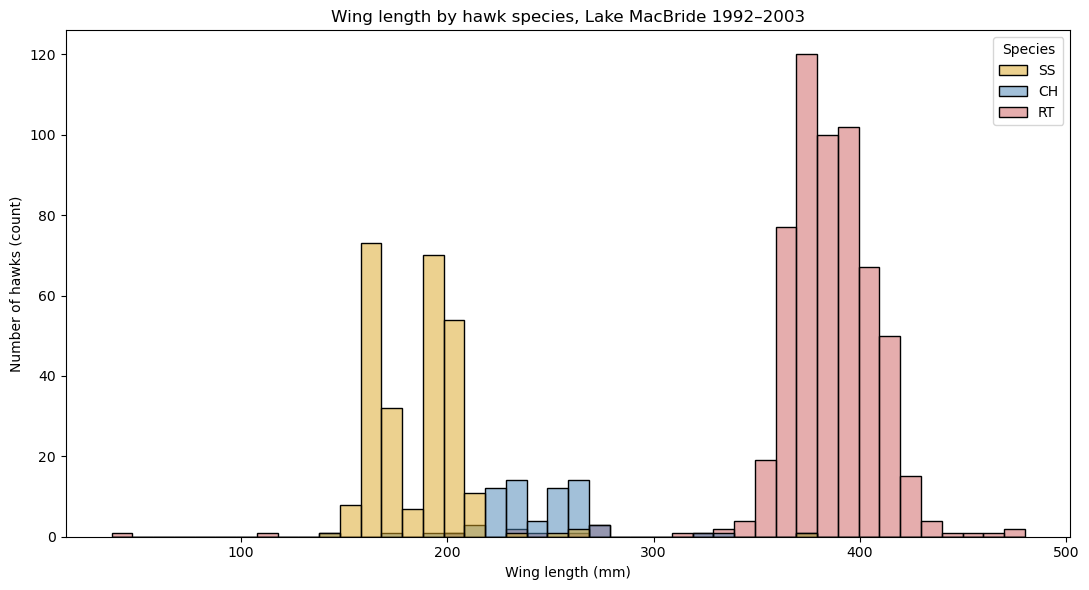

In [10]:
# Create and label the histogram comparison.
plt.figure(figsize=(11, 6))
sns.histplot(data=wing_df, x="Wing", hue="Species",
             hue_order=["SS", "CH", "RT"], palette=["goldenrod", "steelblue", "indianred"], binwidth=10, alpha=0.5)
plt.title("Wing length by hawk species, Lake MacBride 1992–2003")
plt.xlabel("Wing length (mm)")
plt.ylabel("Number of hawks (count)")
plt.tight_layout()
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:

The three species fall in mostly separate places. Sharp-shinned hawks run from about 150 to 210 mm with **two peaks**, near 165 mm and near 195 mm. Cooper's hawks sit between about 220 and 275 mm, with flat, uneven bars. Red-tailed hawks form a tall, roughly symmetric hump from about 350 to 430 mm, peaking near 375–385 mm. Sharp-shinned and Cooper's hawks overlap a little between about 210 and 260 mm. Red-tailed hawks don't overlap the other two except for a few stray bars.

Several bars look out of place: red-tailed hawks near 40 mm, near 110 mm, and a few around 200–280 mm; one sharp-shinned hawk near 370 mm; and Cooper's hawks between 320 and 377 mm. The vertical axis shows counts. With only 69 Cooper's hawks against 577 red-tails, the Cooper's bars are short and their shape is hard to read. Their low height reflects how few were captured, not anything unusual about their wings.

In [11]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
wing_summary = wing_df.groupby("Species")["Wing"].describe().round(1).loc[["SS", "CH", "RT"]]
wing_summary["IQR"] = wing_summary["75%"] - wing_summary["25%"]
wing_summary

,count,mean,std,min,25%,50%,75%,max,IQR
Species,,,,,,,,,
SS,261.0,184.9,22.4,143.0,166.0,191.0,199.0,370.0,33.0
CH,69.0,244.1,32.1,145.0,227.0,240.0,260.0,377.0,33.0
RT,577.0,383.3,31.5,37.2,372.0,384.0,399.0,480.0,27.0


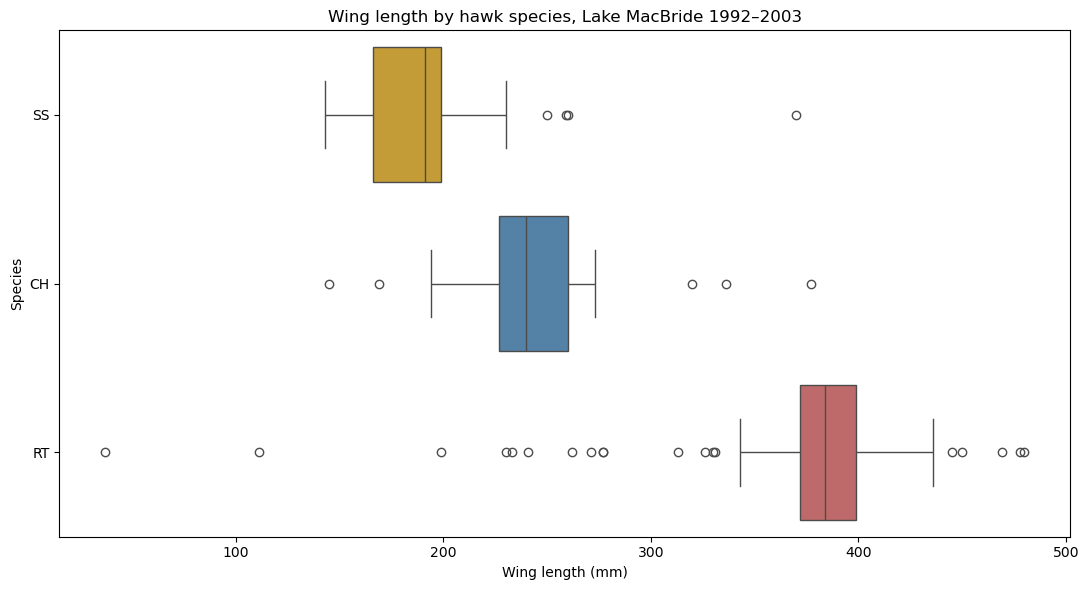

In [12]:
# Create and label the box-plot comparison.
plt.figure(figsize=(11, 6))
sns.boxplot(data=wing_df, x="Wing", y="Species",
            order=["SS", "CH", "RT"], hue="Species", hue_order=["SS", "CH", "RT"],
            palette=["goldenrod", "steelblue", "indianred"], legend=False)
plt.title("Wing length by hawk species, Lake MacBride 1992–2003")
plt.xlabel("Wing length (mm)")
plt.ylabel("Species")
plt.tight_layout()
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:

The summaries line up with the histogram. Median wing lengths are **SS 191 mm, CH 240 mm, and RT 384 mm**, with means close to the medians (184.9, 244.1, and 383.3 mm). The middle 50% of each species has about the same width: IQR = 33 mm for SS (166–199), 33 mm for CH (227–260), and 27 mm for RT (372–399). So red-tails aren't more variable, they're just much larger.

The standard deviations and ranges are pulled by the extreme points. RT's SD of 31.5 mm is nearly as large as CH's 32.1 mm despite RT having the narrowest IQR, because of the 37.2 mm record, and the ranges are misleading (SS max 370 mm, RT min 37.2 mm). The box plot makes the medians and IQRs easy to compare and flags the odd points individually (19 for RT), but it **hides the two sharp-shinned peaks**, which look like one ordinary box. The histogram shows the peaks but makes the small Cooper's group hard to compare.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [13]:
# Perform a targeted check against original records or the declared group definitions.
wing_df.loc[((wing_df["Species"] == "RT") & (wing_df["Wing"] < 300)) |
            ((wing_df["Species"] != "RT") & (wing_df["Wing"] > 300))].join(hawks_df[["Weight", "Culmen", "Tail"]])

,Species,Age,Sex,Wing,Weight,Culmen,Tail
58,RT,I,NaN,241.0,1320.0,28.60,235
60,RT,I,NaN,37.2,1180.0,20.20,210
131,RT,I,NaN,277.0,940.0,26.50,218
278,RT,I,NaN,111.0,1340.0,26.85,226
317,RT,I,NaN,230.0,340.0,16.50,200
321,CH,A,F,377.0,1119.0,25.40,226
324,RT,I,NaN,233.0,337.0,15.70,196
325,CH,I,M,336.0,742.0,23.40,221
329,SS,I,M,370.0,1094.0,27.30,221
413,RT,I,NaN,271.0,NaN,27.40,235


In [14]:
wing_df.groupby(["Species", "Sex"])["Wing"].agg(["count", "median"])

count  median
Species Sex               
CH      F       35   260.0
        M       33   230.0
RT      F        3   410.0
        M        1   381.0
SS      F      136   198.0
        M      124   166.0

In [15]:
wing_df["Species"].value_counts().sum()

np.int64(907)

**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:

I'd be suspicious of a wing length that doesn't fit the bird's species, a value too small to be a real hawk wing, or group counts that don't add up. The first check lists every red-tail with a wing under 300 mm and every SS or CH with a wing over 300 mm, next to the same bird's weight, culmen, and tail, which should agree with the wing.

- **Index 60 (RT, 37.2 mm):** weighs 1,180 g with a 210 mm tail, both normal for a red-tail. A 37 mm wing is impossible for a bird that size, so this is almost certainly a typo for 372 mm.
- **Index 278 (RT, 111 mm) and 907 (RT, 199 mm):** both weigh about 1,300 g, so the wing values are probably also errors.
- **Index 317 and 324 (RT, 230 and 233 mm):** weigh only 340 and 337 g with culmens of 16.5 and 15.7 mm, which are Cooper's-hawk sizes. The species may be recorded wrong.
- **Index 329 (SS, 370 mm, 1,094 g, culmen 27.3 mm) and 321 (CH, 377 mm, 1,119 g, culmen 25.4 mm):** every measurement is red-tail sized, again suggesting the wrong species.
- **Index 58, 131, 413, 602, and 698 (RT, 241–277 mm) and 639 (CH, 320 mm):** the weights and culmens fit their recorded species, so these are either unusual wings or wing typos; I can't tell which. Index 325 (CH, 336 mm, 742 g, culmen 23.4 mm) is large in every measurement, in between a Cooper's hawk and a red-tail.

I can't confirm these against the original field sheets, so I'm keeping all of them as the lab instructs, and I'm relying more on medians and IQRs (barely affected by a few points) than on the mean, SD, or range.

The second check explains the two sharp-shinned peaks: females have a median wing of 198 mm (n = 136) and males 166 mm (n = 124), so the peaks are the two sexes, not a data problem. The same split shows up in Cooper's hawks (F 260 mm vs M 230 mm). Sex can't be checked for red-tails because 573 of 577 have no recorded sex. The counts reconcile: 577 + 261 + 69 = 907, the original 908 minus the one Cooper's hawk without a wing value.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:

Wing length is very different among the three species, in the same order as body size. Sharp-shinned hawks (n = 261) have the shortest wings (median 191 mm, IQR 166–199 mm), Cooper's hawks (n = 69) are in the middle (median 240 mm, IQR 227–260 mm), and red-tailed hawks (n = 577) are far longer (median 384 mm, IQR 372–399 mm), about 144 mm above the Cooper's median. The spreads are similar (IQRs of 27–33 mm). Sharp-shinned and Cooper's wings overlap a bit between about 210 and 260 mm, but red-tails don't overlap either one except for a few records that look like errors. Sharp-shinned wings come in two sex-based clusters, around 166 mm for males and 198 mm for females.

This mostly matches my prediction: the order (SS < CH < RT), the small SS–CH gap with a much bigger gap up to RT, the SS–CH overlap, and the two-humped shape all showed up, but Cooper's hawks were not clearly the most spread out, since their IQR (33 mm) tied with sharp-shinned hawks.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:

A reader shouldn't treat these results as describing the species in general. The hawks were all trapped at one Iowa site, only during fall migration (Aug–Nov), and 684 of the 908 were immature. The documentation calls the data a random sample but doesn't say how the sample was drawn. Sex also affects the comparison: females are larger in all three species, so a species' wing distribution depends partly on how many females and males happened to be caught, and for red-tails that mix is unknown. A few records look like data-entry errors or the wrong species that I couldn't verify, so the ranges and extremes shouldn't be read as real biological limits. Cooper's hawks have only 69 measured birds, so their shape is the least certain.

## Investigation 2

### Step 1: Question


**What is research question 2? Name the quantitative feature, its units, and the categorical groups.**

Your answer:

**How does the distribution of body weight (g) differ among sharp-shinned (SS), Cooper's (CH), and red-tailed (RT) hawks captured at Lake MacBride from 1992 to 2003?** The quantitative feature is `Weight` (body weight in grams), and the groups are the three `Species` codes.

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:

I expect the same pattern as wing length: red-tailed hawks will be the heaviest, sharp-shinned hawks the lightest, and Cooper's hawks in between, with a smaller gap between sharp-shinned and Cooper's hawks and a bigger gap up to red-tailed hawks. I think the heavier species will have a bigger spread in grams. For shape, I expect females to weigh more than males because they store more nutrients, so a species could show two humps like it might for wings. I expect sharp-shinned and Cooper's hawk weights to overlap.

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:

I'll use every hawk with a recorded weight, keeping `Species` and `Weight`. Ten hawks have no weight (5 RT, 5 SS), so they are excluded, leaving 898 hawks. No unit conversions or derived labels are needed; groups keep the same order and colors as Investigation 1 (SS, CH, RT). Weight is in grams as documented, no values are zero, and there are no special missing codes. Unusual values stay in and get checked in Step 4. One analyzed observation is one captured hawk's body weight. `hawks_df` itself is left unchanged.

In [16]:
# Prepare this question's analysis DataFrame and preview the selected features.
weight_df = hawks_df.loc[hawks_df["Weight"].notna(), ["Species", "Age", "Sex", "Weight"]].copy()
weight_df.head()

,Species,Age,Sex,Weight
0,RT,I,NaN,920.0
1,RT,I,NaN,930.0
2,RT,I,NaN,990.0
3,CH,I,F,470.0
4,SS,I,F,170.0


In [17]:
# Display the number of usable observations in each group.
weight_df["Species"].value_counts()

Species
RT    572
SS    256
CH     70
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


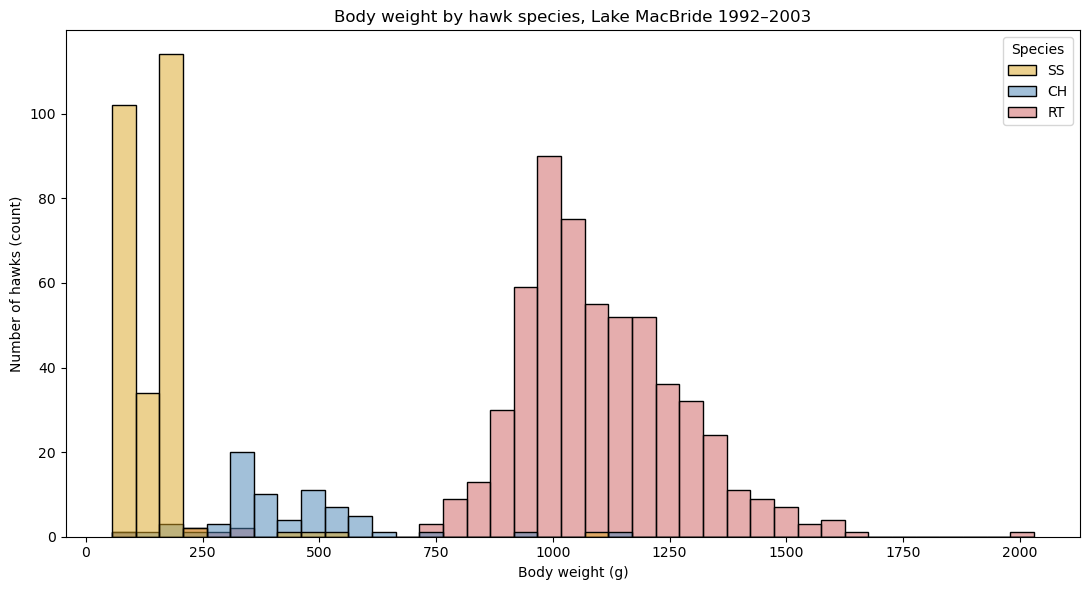

In [18]:
# Create and label the histogram comparison.
plt.figure(figsize=(11, 6))
sns.histplot(data=weight_df, x="Weight", hue="Species",
             hue_order=["SS", "CH", "RT"], palette=["goldenrod", "steelblue", "indianred"], binwidth=50, alpha=0.5)
plt.title("Body weight by hawk species, Lake MacBride 1992–2003")
plt.xlabel("Body weight (g)")
plt.ylabel("Number of hawks (count)")
plt.tight_layout()
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:

The species are even more separated by weight than by wing length. Sharp-shinned hawks are packed at the far left under about 250 g, with two tall bars near 100 g and near 175 g, which looks like the male/female split again. Cooper's hawks spread from about 300 to 650 g, with a peak around 330–380 g and a smaller one around 500 g. Red-tailed hawks form a broad hump from about 750 to 1,650 g that peaks near 1,000–1,050 g and stretches a bit further to the right (heavier birds). Sharp-shinned and Cooper's hawks barely touch, and red-tails don't overlap either except for stray bars.

Unusual values include a few sharp-shins between 400 and 1,100 g, red-tails below 400 g, one red-tail near 2,000 g, and Cooper's hawks near 50 g and above 900 g. The vertical axis shows counts. Cooper's hawks (70) are again the hardest to read: their tallest bar holds 20 birds while the tallest red-tail bar holds about 90.

In [19]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
weight_summary = weight_df.groupby("Species")["Weight"].describe().round(1).loc[["SS", "CH", "RT"]]
weight_summary["IQR"] = weight_summary["75%"] - weight_summary["25%"]
weight_summary

,count,mean,std,min,25%,50%,75%,max,IQR
Species,,,,,,,,,
SS,256.0,148.0,80.7,85.0,100.0,155.0,177.8,1094.0,77.8
CH,70.0,420.5,162.0,56.0,335.0,377.5,505.0,1119.0,170.0
RT,572.0,1094.4,189.2,101.0,980.0,1070.0,1210.0,2030.0,230.0


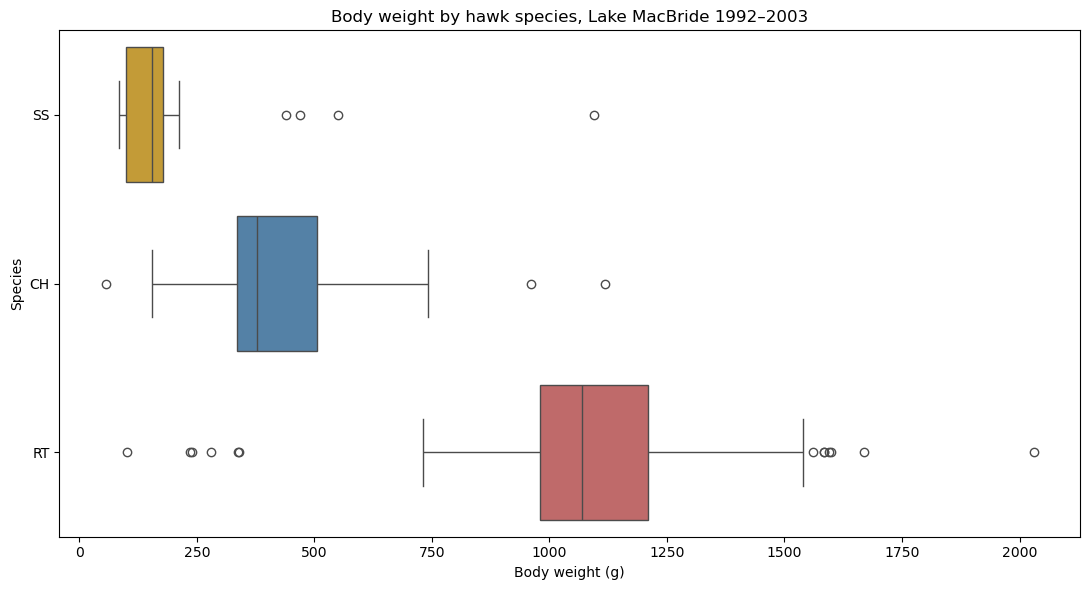

In [20]:
# Create and label the box-plot comparison.
plt.figure(figsize=(11, 6))
sns.boxplot(data=weight_df, x="Weight", y="Species",
            order=["SS", "CH", "RT"], hue="Species", hue_order=["SS", "CH", "RT"],
            palette=["goldenrod", "steelblue", "indianred"], legend=False)
plt.title("Body weight by hawk species, Lake MacBride 1992–2003")
plt.xlabel("Body weight (g)")
plt.ylabel("Species")
plt.tight_layout()
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:

The summaries match the histogram. Median weights are **SS 155 g, CH 377.5 g, and RT 1,070 g**. Unlike wing length, spread grows with size: IQR = 77.8 g for SS (100–177.8), 170 g for CH (335–505), and 230 g for RT (980–1,210). Relative to its center, though, SS is the most variable (its IQR is about half its median) because light males (around 100 g) and heavy females (around 175 g) are mixed together.

The means are pulled toward the extremes: CH's mean is 420.5 g against a 377.5 g median, and SS's mean (148 g) sits below its median (155 g) because the large cluster of light males outweighs the few heavy outliers. The SDs are inflated by single records; SS's 80.7 g SD is mostly due to one 1,094 g bird. The box plot flags 4 SS, 3 CH, and 13 RT points and clearly shows that the boxes don't overlap, but it squeezes sharp-shins into a thin box and hides their two clusters. The histogram shows the clusters, but on a 0–2,000 g axis the sharp-shin shape is squeezed into three or four bars.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [21]:
# Perform a targeted check against original records or the declared group definitions.
weight_df.loc[((weight_df["Species"] == "RT") & (weight_df["Weight"] < 600)) |
              ((weight_df["Species"] == "SS") & (weight_df["Weight"] > 300)) |
              ((weight_df["Species"] == "CH") & ((weight_df["Weight"] < 200) | (weight_df["Weight"] > 800)))].join(hawks_df[["Wing", "Culmen", "Tail"]])

,Species,Age,Sex,Weight,Wing,Culmen,Tail
22,RT,I,NaN,101.0,415.0,24.9,238
187,CH,A,M,183.0,239.0,17.3,182
317,RT,I,NaN,340.0,230.0,16.5,200
318,CH,I,M,163.0,194.0,12.2,158
320,SS,I,M,550.0,260.0,19.5,215
321,CH,A,F,1119.0,377.0,25.4,226
324,RT,I,NaN,337.0,233.0,15.7,196
326,SS,I,F,439.0,259.0,18.8,218
327,CH,I,F,187.0,199.0,12.2,157
329,SS,I,M,1094.0,370.0,27.3,221


In [22]:
weight_df.groupby(["Species", "Sex"])["Weight"].agg(["count", "median"])

count  median
Species Sex               
CH      F       35   490.0
        M       33   340.0
RT      F        3  1120.0
        M        1  1080.0
SS      F      132   175.0
        M      123   100.0

In [23]:
hawks_df.loc[hawks_df["Weight"].isna(), "Species"].value_counts()

Species
RT    5
SS    5
Name: count, dtype: int64

**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:

I'd be suspicious of a weight far outside the species' usual range, especially if the same bird's wing and bill don't match it, or of missing weights concentrated in one species. I chose the cutoffs (RT < 600 g, SS > 300 g, CH < 200 g or > 800 g) at gaps in the histogram. The flagged birds fall into three kinds:

- **Weight is wrong, but the other measurements fit the species:** index 22 (RT, 101 g, normal 415 mm wing, probably a typo for 1,010 g); index 489, 644, and 702 (RT, 280, 235, and 240 g with red-tail wings of 378–404 mm); index 510 (CH, 56 g, 268 mm wing); index 719 (CH, 960 g, 255 mm wing).
- **All measurements fit a different species:** index 317 and 324 (RT, about 340 g, Cooper's-sized wing and bill, also flagged in Investigation 1); index 320, 326, and 541 (SS, 439–550 g, with 250–260 mm wings and about 19 mm culmens, which is Cooper's size; the two species are known to be hard to tell apart); index 321 (CH, 1,119 g) and 329 (SS, 1,094 g), red-tail-sized in every measurement.
- **Small but consistent Cooper's hawks:** index 187, 318, 327, and 641 (155–187 g) also have small wings and bills, so they are probably real small males.

As before, I can't verify these against the field records, so I'm keeping them and relying on medians and IQRs. The sex check confirms the two sharp-shin clusters: females have a median of 175 g (n = 132) and males 100 g (n = 123), and Cooper's hawks also split (F 490 g, M 340 g). The ten missing weights are 5 RT and 5 SS, so dropping them barely changes any group. The counts reconcile: 572 + 256 + 70 = 898 = 908 − 10.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:

Body weight completely separates the middle 50% of the three species. Sharp-shinned hawks (n = 256) are lightest (median 155 g, IQR 100–177.8 g), Cooper's hawks (n = 70) are in the middle (median 377.5 g, IQR 335–505 g), and red-tailed hawks (n = 572) are heaviest (median 1,070 g, IQR 980–1,210 g), nearly seven times the sharp-shin median. The IQRs don't overlap at all, and only a handful of records that look like errors fall in another species' range. Absolute spread grows with size (IQRs of 77.8, 170, and 230 g). Sharp-shins form two sex-based clusters (about 100 g for males and 175 g for females), and Cooper's hawks split the same way. Compared with wing length, weight shows larger relative differences: the red-tail median weight is 2.8 times the Cooper's median, while the red-tail median wing is only 1.6 times longer.

This mostly matches my prediction: the order (SS < CH < RT), the smaller SS–CH gap (median 155 g vs 377.5 g) with a much bigger gap up to RT (1,070 g), spread growing with weight (IQRs of 77.8, 170, and 230 g), and females weighing more (SS 175 g vs 100 g; CH 490 g vs 340 g) all showed up, but sharp-shinned and Cooper's weights barely overlapped, since their IQRs don't touch and only a few likely-misidentified birds cross between them.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:

A reader shouldn't treat these as typical adult weights for each species. Weight changes with condition (how recently a bird ate and how much fat it carries). The dataset records this in `Crop` and `KeelFat`, but those are missing for about 340 birds, and I didn't account for them. All birds were fall migrants at one Iowa site and mostly immature (immature red-tails have a median of 1,050 g vs 1,120 g for adults). Sex can't be checked for nearly all red-tails, and females are heavier in all three species, so each sample's sex mix affects its distribution. Several records appear to have the wrong weight or species; they're kept, so the minimums, maximums, means, and SDs here shouldn't be taken as real species limits. With only 70 weighed Cooper's hawks, their two-peak shape could look different with more data.

## Investigation 3

### Step 1: Question


**What is research question 3? Name the quantitative feature, its units, and the categorical groups.**

Your answer:

**How does the distribution of culmen length (mm) differ among sharp-shinned (SS), Cooper's (CH), and red-tailed (RT) hawks captured at Lake MacBride from 1992 to 2003?** The quantitative feature is `Culmen` (length of the upper bill from the tip to where it meets the fleshy cere, in millimeters), and the groups are the three `Species` codes.

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:

I expect the same pattern as wing length and weight: red-tailed hawks will have the longest bills, sharp-shinned hawks the shortest, and Cooper's hawks in between, with a smaller gap between sharp-shinned and Cooper's hawks and a bigger gap up to red-tailed hawks. I think the bigger species will have a bigger spread. For shape, I think males and females will have about the same bill length, so each species will be one smooth hump. I expect sharp-shinned and Cooper's hawks to overlap, since they look similar and are mainly different sizes.

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:

I'll use every hawk with a recorded culmen, keeping `Species` and `Culmen`. Seven hawks have no culmen (4 RT, 3 SS), so they are excluded, leaving 901 hawks. No conversions or derived labels are needed; the species order and colors stay the same (SS, CH, RT). Culmen is in millimeters as documented, almost always recorded to one decimal place, and no values are zero. Unusual values stay in and get checked in Step 4. One analyzed observation is one captured hawk's bill length. `hawks_df` itself is left unchanged.

In [24]:
# Prepare this question's analysis DataFrame and preview the selected features.
culmen_df = hawks_df.loc[hawks_df["Culmen"].notna(), ["Species", "Age", "Sex", "Culmen"]].copy()
culmen_df.head()

,Species,Age,Sex,Culmen
0,RT,I,NaN,25.7
2,RT,I,NaN,26.7
3,CH,I,F,18.7
4,SS,I,F,12.5
5,RT,I,NaN,28.5


In [25]:
# Display the number of usable observations in each group.
culmen_df["Species"].value_counts()

Species
RT    573
SS    258
CH     70
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


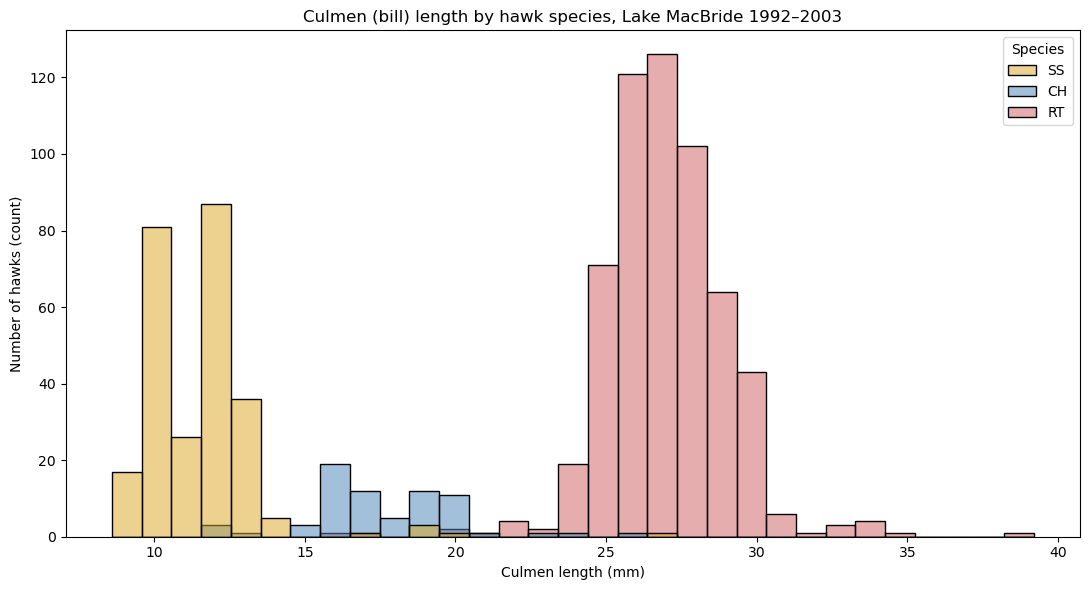

In [26]:
# Create and label the histogram comparison.
plt.figure(figsize=(11, 6))
sns.histplot(data=culmen_df, x="Culmen", hue="Species",
             hue_order=["SS", "CH", "RT"], palette=["goldenrod", "steelblue", "indianred"], binwidth=1, alpha=0.5)
plt.title("Culmen (bill) length by hawk species, Lake MacBride 1992–2003")
plt.xlabel("Culmen length (mm)")
plt.ylabel("Number of hawks (count)")
plt.tight_layout()
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:

The three species form three separate clusters. Sharp-shinned hawks sit at about 9–14 mm with two peaks, near 10 mm and near 12 mm (the sex split again). Cooper's hawks spread from about 15 to 21 mm, with low, uneven bars and possible peaks near 16 mm and 19–20 mm. Red-tailed hawks form a tall, fairly symmetric hump from about 24 to 31 mm, peaking around 26–27 mm. Sharp-shins and Cooper's hawks hardly overlap, and red-tails overlap neither.

Stray values include a few sharp-shins at 16–20 mm, red-tails between 15 and 23 mm, red-tails out at 32–35 mm, and one red-tail near 39 mm. The vertical axis shows counts, and as before the 70 Cooper's hawks are hard to compare with the 573 red-tails.

In [27]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
culmen_summary = culmen_df.groupby("Species")["Culmen"].describe().round(1).loc[["SS", "CH", "RT"]]
culmen_summary["IQR"] = culmen_summary["75%"] - culmen_summary["25%"]
culmen_summary

,count,mean,std,min,25%,50%,75%,max,IQR
Species,,,,,,,,,
SS,258.0,11.5,1.9,8.6,10.0,11.7,12.3,27.3,2.3
CH,70.0,17.6,2.4,12.2,16.0,17.1,19.2,25.4,3.2
RT,573.0,27.0,2.1,15.7,25.8,26.8,28.1,39.2,2.3


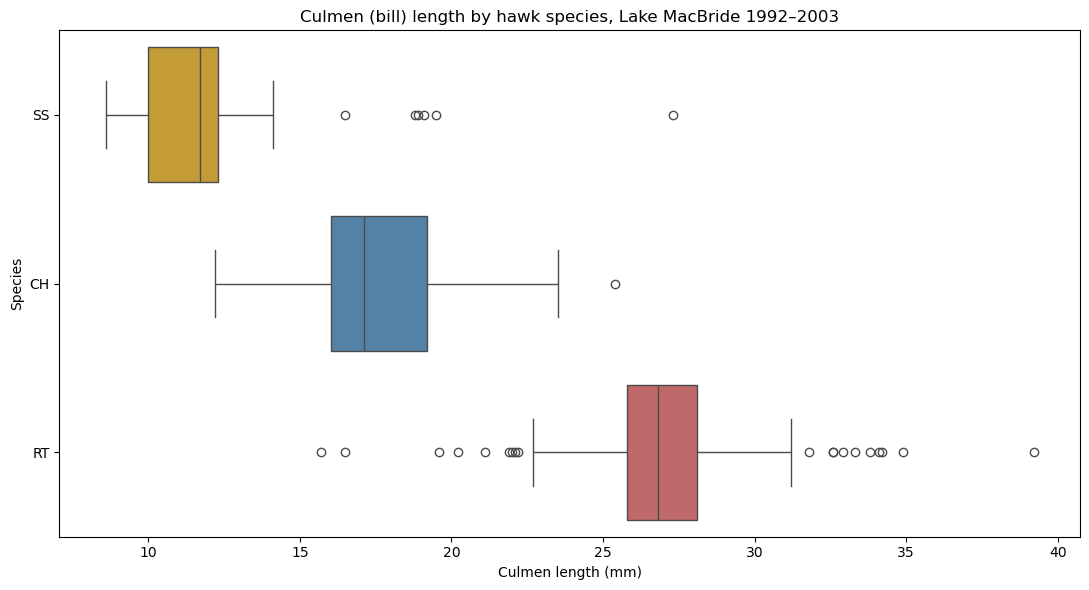

In [28]:
# Create and label the box-plot comparison.
plt.figure(figsize=(11, 6))
sns.boxplot(data=culmen_df, x="Culmen", y="Species",
            order=["SS", "CH", "RT"], hue="Species", hue_order=["SS", "CH", "RT"],
            palette=["goldenrod", "steelblue", "indianred"], legend=False)
plt.title("Culmen (bill) length by hawk species, Lake MacBride 1992–2003")
plt.xlabel("Culmen length (mm)")
plt.ylabel("Species")
plt.tight_layout()
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:

The summaries closely match the histogram. Median culmens are **SS 11.7 mm, CH 17.1 mm, and RT 26.8 mm**, and each mean is within half a millimeter of its median (11.5, 17.6, and 27.0 mm). Spreads are small and similar: IQR = 2.3 mm for SS (10.0–12.3), 3.2 mm for CH (16.0–19.2), and 2.3 mm for RT (25.8–28.1). Cooper's hawks are the most spread out, which fits their flat, two-peaked look in the histogram.

This time the SDs (1.9, 2.4, and 2.1 mm) are close to the IQRs, because the few extreme values are small compared with the group sizes. The box plot flags 6 SS, 1 CH, and 19 RT points; most of the red-tail points sit just past the whiskers (22 mm and 32–35 mm) because a narrow IQR also means short whiskers. The box plot shows that no IQRs overlap but hides the two-peak shapes in sharp-shins and Cooper's hawks. The histogram shows them, but with 1 mm bins, a Cooper's peak of only 10–20 birds could easily be noise.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [29]:
# Perform a targeted check against original records or the declared group definitions.
culmen_df.loc[((culmen_df["Species"] == "RT") & (culmen_df["Culmen"] < 20)) |
              ((culmen_df["Species"] == "SS") & (culmen_df["Culmen"] > 16)) |
              ((culmen_df["Species"] == "CH") & ((culmen_df["Culmen"] < 13) | (culmen_df["Culmen"] > 23)))].join(hawks_df[["Wing", "Weight", "Tail"]])

,Species,Age,Sex,Culmen,Wing,Weight,Tail
87,RT,I,NaN,19.6,385.0,1125.0,233
151,SS,I,M,19.1,171.0,100.0,134
286,CH,I,M,12.6,225.0,350.0,215
304,SS,I,F,16.5,191.0,155.0,158
317,RT,I,NaN,16.5,230.0,340.0,200
318,CH,I,M,12.2,194.0,163.0,158
320,SS,I,M,19.5,260.0,550.0,215
321,CH,A,F,25.4,377.0,1119.0,226
324,RT,I,NaN,15.7,233.0,337.0,196
325,CH,I,M,23.4,336.0,742.0,221


In [30]:
culmen_df.groupby(["Species", "Sex"])["Culmen"].agg(["count", "median"])

count  median
Species Sex               
CH      F       35    19.1
        M       33    16.1
RT      F        3    28.5
SS      F      135    12.2
        M      122    10.0

In [31]:
hawks_df.loc[hawks_df["Culmen"].isna(), "Species"].value_counts()

Species
RT    4
SS    3
Name: count, dtype: int64

**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:

I'd be suspicious of a bill length that doesn't fit the bird's species (especially if its wing and weight disagree) or of a measurement recorded in the wrong unit, such as a red-tail culmen of 2.7 that would point to centimeters. All values fall between 8.6 and 39.2 mm, which is plausible for hawk bills, so there's no sign of a unit problem. I chose the cutoffs (RT < 20 mm, SS > 16 mm, CH < 13 mm or > 23 mm) at gaps in the histogram. The flagged birds fall into three kinds:

- **The same birds flagged in Investigations 1 and 2:** index 317 and 324 (RT, 16.5 and 15.7 mm) have Cooper's-sized bills, wings, and weights; index 320, 326, and 541 (SS, 18.8–19.5 mm) have Cooper's-sized bills matching their Cooper's-sized wings and weights; index 321 (CH, 25.4 mm) and 329 (SS, 27.3 mm) are red-tail-sized in every measurement. With all three measurements now pointing to a different species, these seven birds most likely have the wrong **species label**, not wrong measurements.
- **Only the culmen is odd:** index 151 (SS male, 19.1 mm) has a normal sharp-shin wing (171 mm) and weight (100 g), so the culmen may be a typo for 9.1 mm. Index 304 (SS, 16.5 mm) and 87 (RT, 19.6 mm) are similar cases of an odd bill on an otherwise normal bird.
- **Small but consistent:** index 286, 318, 327, and 741 are Cooper's hawks with 12.2–12.6 mm culmens, and most also have small wings and weights, so they're probably real small birds. Index 325 (CH, 23.4 mm) is large in every measurement, as in Investigation 1, while index 357 (CH, 23.5 mm) has a normal Cooper's wing (213 mm) and weight (339 g), so its bill is the odd value.

I'm keeping all records. The sex check again explains the two sharp-shin peaks: females have a median of 12.2 mm (n = 135) and males 10.0 mm (n = 122), and Cooper's hawks split too (F 19.1 mm, M 16.1 mm). The seven missing culmens are 4 RT and 3 SS, so no group loses much. The counts reconcile: 573 + 258 + 70 = 901 = 908 − 7.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:

Culmen length clearly separates the three species. Sharp-shinned hawks (n = 258) have the shortest bills (median 11.7 mm, IQR 10.0–12.3 mm), Cooper's hawks (n = 70) are in the middle (median 17.1 mm, IQR 16.0–19.2 mm), and red-tailed hawks (n = 573) are longest (median 26.8 mm, IQR 25.8–28.1 mm). The IQRs don't overlap, with wide gaps between them (3.7 mm between SS and CH, 6.6 mm between CH and RT). Spreads are similar (IQRs of 2.3–3.2 mm), so the groups differ in center, not in how variable they are. The species order matches wing length and weight, sharp-shins again split by sex (about 10 mm for males and 12 mm for females), and Cooper's hawks are the most variable group.

This partly matches my prediction: the order (SS < CH < RT) and the smaller SS–CH gap (median 11.7 mm vs 17.1 mm) with a bigger gap up to RT (26.8 mm) showed up, but the spread did not grow with size (IQRs of 2.3, 3.2, and 2.3 mm, with Cooper's the widest), sexes did differ enough to make two humps in sharp-shinned hawks (F 12.2 mm vs M 10.0 mm), and sharp-shinned and Cooper's bills hardly overlapped except for a few likely-misidentified birds.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:

A reader shouldn't conclude that bill length alone can identify a hawk's species. Several birds have bills that fit a different species, and Cooper's females (median 19.1 mm) aren't far from the smallest red-tails. The species labels themselves look unreliable for at least seven birds, so some apparent overlap may be labeling errors rather than real biological overlap, and I can't tell which. The documentation doesn't describe how culmen was measured or whether the same people measured it each year, so differences between measurers could add spread. The same limits from Investigations 1 and 2 also apply: fall migrants at one Iowa site, mostly immature birds, red-tails almost never sexed, and only 70 Cooper's hawks.

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:

Yes. I used Claude throughout this lab: it helped me choose the dataset and reviewed and expanded the code and written answers. The suggestion I checked was the dataset choice. Claude suggested several candidates, and when I asked about hawks it proposed the Stat2Data Hawks data. I checked that it met the lab's requirements by looking at the Rdatasets documentation page (named source, units for Wing, Weight, and Culmen, and three species codes) and by confirming the species counts with `hawks_df["Species"].value_counts()`, which showed RT 577, SS 261, and CH 70. I accepted the suggestion and grouped by Species instead of Sex, because Sex was missing for 576 hawks.

## Submission checklist

- Include the new dataset CSV, source citation, dictionary reference, and explanation of why it has not been used in class or a previous lab.
- Document every feature, including meaning, units/codes, conceptual type, storage type, and missing count.
- Identify at least one categorical feature and three distinct quantitative features.
- Complete three different questions, one quantitative feature per question, each with a prediction and all six workflow steps.
- Include a histogram and box plot for each question, grouped summaries and IQRs, and usable group sizes.
- Explain preparation and exclusions; preserve valid extreme values and distinguish missing values from zero.
- Support conclusions about similarities or differences with numerical and visual evidence, contextual checks, and specific limitations.
- Complete every written response and the AI-use reflection.
- Restart the kernel and run every cell in order; use relative paths and ensure all claims match the output.
